# Mall Shopper Profiling — Unsupervised Learning
Clustering mall customers with **K-Means**, **Agglomerative Hierarchical Clustering** and **DBSCAN**, then turning the clusters into retail personas and strategies.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Step 1: Dataset Loading & EDA
## 1.1 Load & Inspect

In [2]:
df = pd.read_csv('Dataset/Mall_Customers.csv')
print(df.shape)
df.info()
df.head(10)

(200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [3]:
df = df.rename(columns={'Genre': 'Gender',
                        'Annual Income (k$)': 'AnnualIncome',
                        'Spending Score (1-100)': 'SpendingScore'})
print(df.isnull().sum())
print(df['Gender'].value_counts())

CustomerID       0
Gender           0
Age              0
AnnualIncome     0
SpendingScore    0
dtype: int64
Gender
Female    112
Male       88
Name: count, dtype: int64


**Findings.** The dataset has 200 rows and 5 columns (CustomerID, Genre, Age, Annual Income, Spending Score). There are **no missing values**. Gender split: **112 Female (56%)** and **88 Male (44%)**. Columns were renamed to `Gender`, `AnnualIncome`, `SpendingScore`.

## 1.2 Univariate Analysis

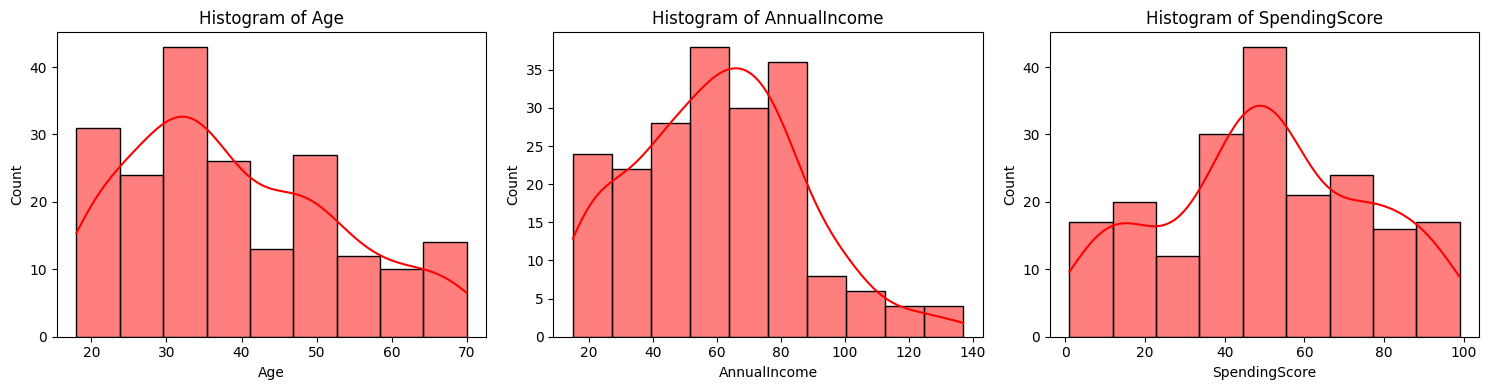

In [4]:
num_cols = ['Age', 'AnnualIncome', 'SpendingScore']

plt.figure(figsize=(15, 4))
for i, col in enumerate(num_cols):
    plt.subplot(1, 3, i + 1)
    sns.histplot(df[col], kde=True, color='red')
    plt.title(f'Histogram of {col}')
plt.tight_layout()
plt.savefig('histograms.png')
plt.show()

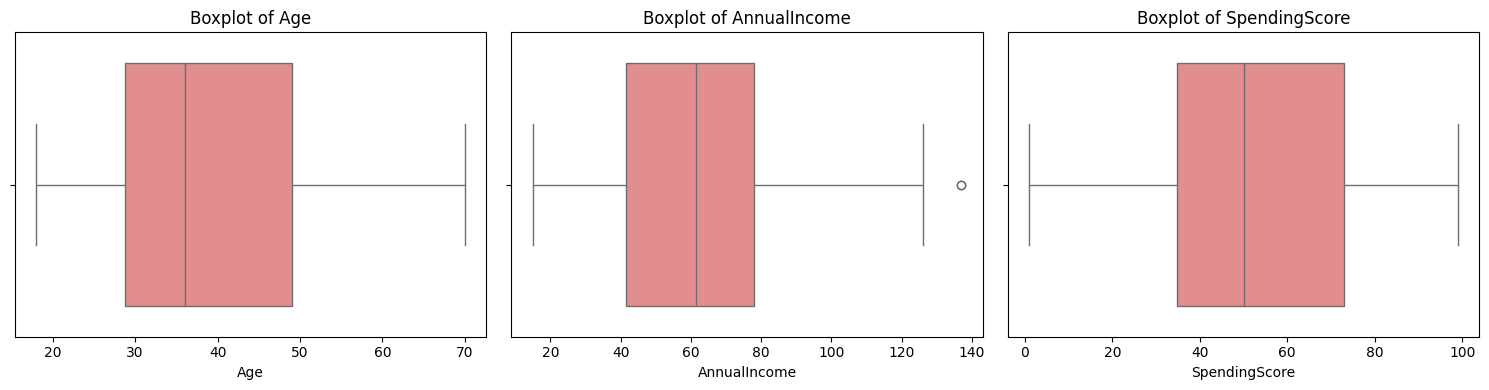

In [5]:
plt.figure(figsize=(15, 4))
for i, col in enumerate(num_cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x=df[col], color='lightcoral')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.savefig('boxplots.png')
plt.show()

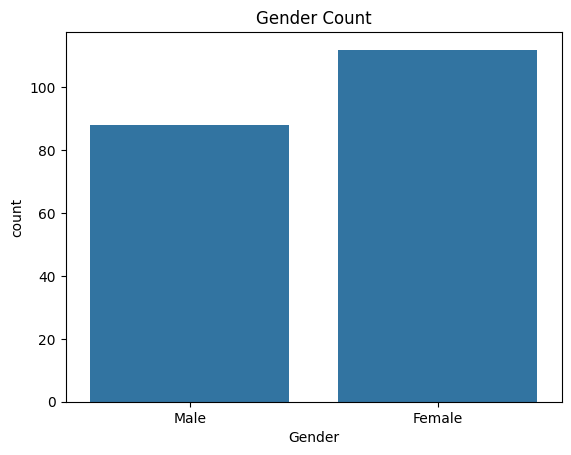

In [6]:
sns.countplot(x='Gender', data=df)
plt.title('Gender Count')
plt.savefig('gender_count.png')
plt.show()

**Distributions**
- **Age** is right-skewed (skew 0.49): most shoppers are 25–50, with a thinner tail up to 70.
- **AnnualIncome** is mildly right-skewed (0.32) and roughly bell-shaped, centred near 60 k$.
- **SpendingScore** is nearly symmetric (skew −0.05) and spread widely across 1–99, with no single dominant peak.

**Outliers.** Only AnnualIncome shows any (2 customers at 137 k$ by the 1.5×IQR rule); Age and SpendingScore have none. These two are high earners, not data errors, so they are kept.

**Gender balance.** The dataset is reasonably balanced (56% / 44%), with slightly more women.

## 1.3 Bivariate Analysis

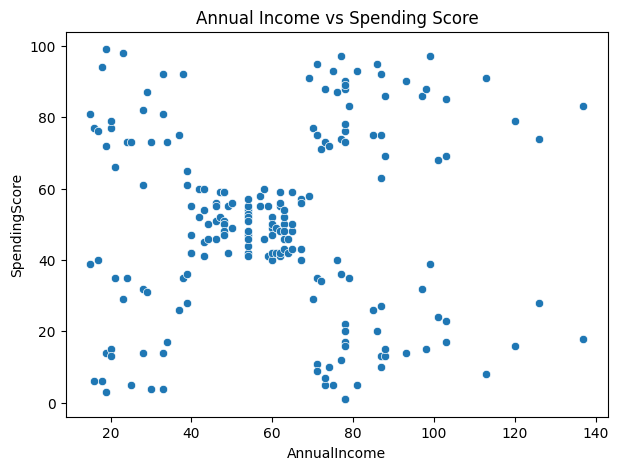

In [7]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='AnnualIncome', y='SpendingScore', data=df)
plt.title('Annual Income vs Spending Score')
plt.savefig('annual_income_vs_spending_score.png')
plt.show()

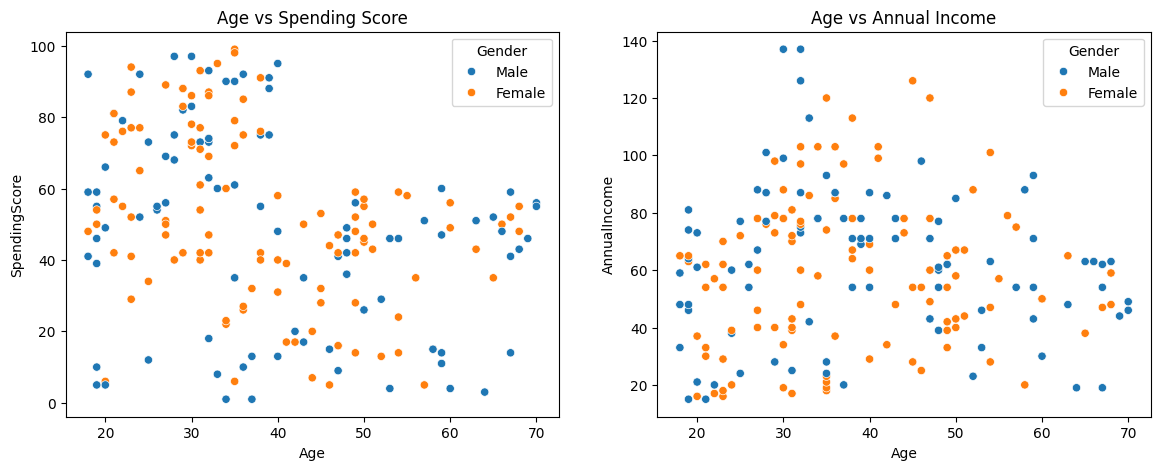

In [8]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x='Age', y='SpendingScore', hue='Gender', data=df)
plt.title('Age vs Spending Score')
plt.subplot(1, 2, 2)
sns.scatterplot(x='Age', y='AnnualIncome', hue='Gender', data=df)
plt.title('Age vs Annual Income')
plt.savefig('age_vs_spending_score.png')
plt.show()

                    Age  AnnualIncome  SpendingScore
Age            1.000000     -0.012398      -0.327227
AnnualIncome  -0.012398      1.000000       0.009903
SpendingScore -0.327227      0.009903       1.000000


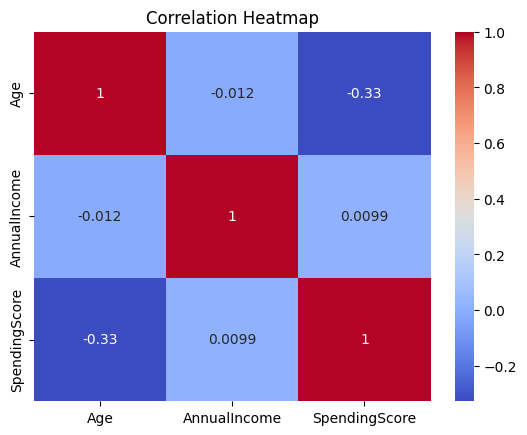

In [9]:
corr = df[num_cols].corr()
print(corr)
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.savefig('correlation_heatmap.png')
plt.show()

**Visual groupings.** In **AnnualIncome vs SpendingScore** five compact groups are visible before any algorithm runs:
1. a central blob (income ≈ 40–70, spending ≈ 40–60),
2. top-right: high income, high spending,
3. bottom-right: high income, low spending,
4. top-left: low income, high spending,
5. bottom-left: low income, low spending.

The Age-based scatter plots show no such structure, only that high spenders tend to be younger.

**Correlations.** All are weak. Age vs SpendingScore is the strongest (**−0.33**, older shoppers spend a bit less); AnnualIncome vs SpendingScore is essentially **0.01** and Age vs AnnualIncome **−0.01**. Income does not predict spending, which is exactly why a 2D clustering on those two features reveals distinct personas.

## 1.4 Gender-Wise Summary

              Age  AnnualIncome  SpendingScore
Gender                                        
Female  38.098214     59.250000      51.526786
Male    39.806818     62.227273      48.511364


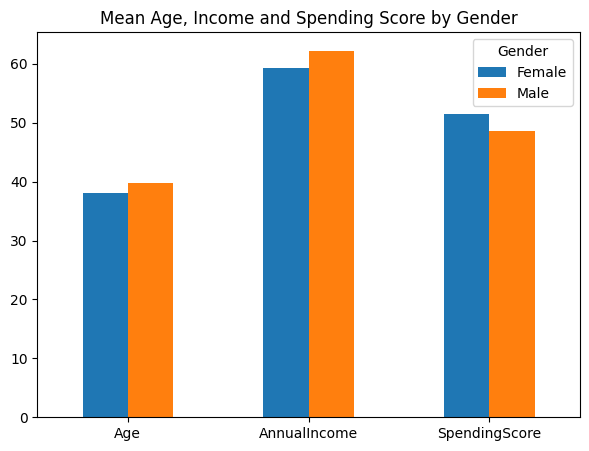

In [10]:
gender_summary = df.groupby('Gender')[num_cols].mean()
print(gender_summary)
gender_summary.T.plot(kind='bar', figsize=(7, 5))
plt.title('Mean Age, Income and Spending Score by Gender')
plt.xticks(rotation=0)
plt.savefig('gender_summary.png')
plt.show()

**Gender differences are small.** Women have a slightly higher mean SpendingScore (51.5 vs 48.5) and a slightly lower mean income (59.3 vs 62.2 k$) and age (38.1 vs 39.8). These gaps are only about 3 points on 100, so gender is not a strong driver of segmentation, which is consistent with the weak 5D result later.

# Step 2: Feature Engineering & Preprocessing
## 2.1 Encode Gender

In [11]:
df['Gender_enc'] = df['Gender'].map({'Female': 0, 'Male': 1})
df[['Gender', 'Gender_enc']].head()

,Gender,Gender_enc
0,Male,1
1,Male,1
2,Female,0
3,Female,0
4,Female,0


## 2.2 Engineer New Features

In [12]:
df['IncomeGroup'] = pd.qcut(df['AnnualIncome'], q=3, labels=['Low', 'Medium', 'High'])
df['AgeGroup'] = pd.cut(df['Age'], bins=[17, 25, 40, 55, 100], labels=['Young', 'Adult', 'Middle-Aged', 'Senior'])
df['SpendingCategory'] = pd.cut(df['SpendingScore'], bins=[0, 33, 66, 100], labels=['Low', 'Medium', 'High'])

print(df['IncomeGroup'].value_counts())
print(df['AgeGroup'].value_counts())
print(df['SpendingCategory'].value_counts())

IncomeGroup
Low       70
High      66
Medium    64
Name: count, dtype: int64
AgeGroup
Adult          84
Middle-Aged    49
Young          38
Senior         29
Name: count, dtype: int64
SpendingCategory
Medium    94
High      57
Low       49
Name: count, dtype: int64


**Bin balance.** `IncomeGroup` is almost perfectly balanced (Low 70 / Medium 64 / High 66) because `qcut` makes equal-frequency bins. `SpendingCategory` is centre-heavy (Low 49 / Medium 94 / High 57) and `AgeGroup` is skewed to Adults (Young 38 / Adult 84 / Middle-Aged 49 / Senior 29), reflecting the real distributions. Fixed-width bins (`cut`) therefore are not balanced, equal-frequency bins (`qcut`) are.

## 2.3 Select Features

In [13]:
X_2d = df[['AnnualIncome', 'SpendingScore']]
X_5d = df[['Age', 'AnnualIncome', 'SpendingScore', 'Gender_enc']]
print(X_2d.shape, X_5d.shape)

(200, 2) (200, 4)


**Experiment A (2D)** uses `AnnualIncome` and `SpendingScore`, the pair with visible structure. **Experiment B** uses `Age`, `AnnualIncome`, `SpendingScore` and `Gender_enc` (named "5D" in the brief, although it has 4 columns). `Gender_enc` is binary and is scaled along with the rest so every feature carries unit variance.

## 2.4 Scale the Features

In [14]:
scaler_2d = StandardScaler()
scaler_5d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)
X_5d_scaled = scaler_5d.fit_transform(X_5d)

print('2D mean:', X_2d_scaled.mean(axis=0).round(2), 'std:', X_2d_scaled.std(axis=0).round(2))
print('5D mean:', X_5d_scaled.mean(axis=0).round(2), 'std:', X_5d_scaled.std(axis=0).round(2))

2D mean: [-0. -0.] std: [1. 1.]
5D mean: [-0. -0. -0.  0.] std: [1. 1. 1. 1.]


# Step 3: K-Means Clustering
## 3.1 Elbow Method & Silhouette Score

    k     Inertia  Silhouette
0   2  269.691012    0.321271
1   3  157.704008    0.466585
2   4  108.921317    0.493907
3   5   65.568408    0.554657
4   6   55.057348    0.539880
5   7   44.864756    0.528149
6   8   37.228188    0.455215
7   9   32.392268    0.457085
8  10   29.981898    0.443171


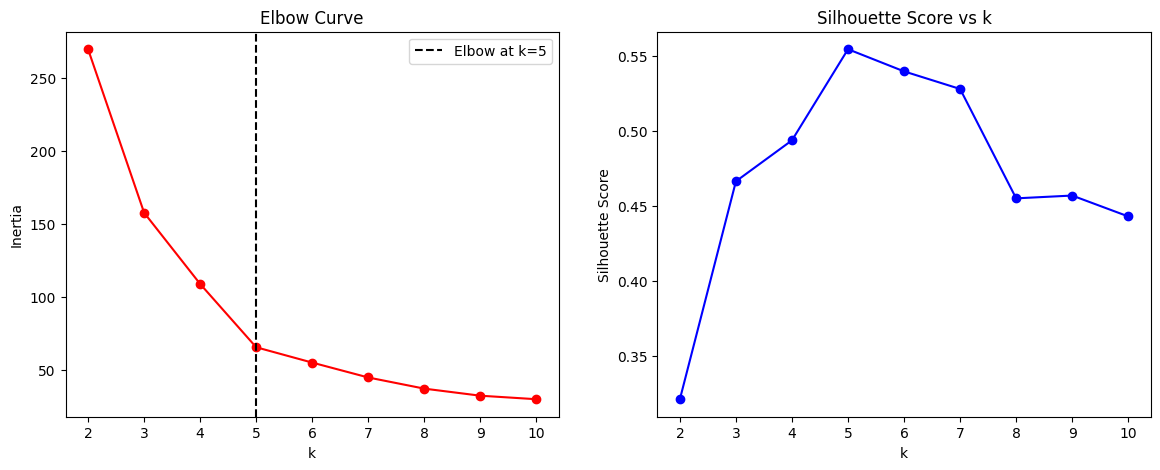

In [15]:
inertia = []
sil_scores = []
k_values = range(2, 11)

for k in k_values:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_2d_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_2d_scaled, km.labels_))

print(pd.DataFrame({'k': k_values, 'Inertia': inertia, 'Silhouette': sil_scores}))

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(k_values, inertia, marker='o', color='red')
plt.axvline(x=5, color='black', linestyle='--', label='Elbow at k=5')
plt.title('Elbow Curve')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(k_values, sil_scores, marker='o', color='blue')
plt.title('Silhouette Score vs k')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.savefig('elbow_silhouette.png')
plt.show()

k_optimal = 5

**Choice of k = 5.** The elbow is at k = 5, where inertia drops from 108.9 (k=4) to 65.6 and then flattens (55.1 at k=6). The Silhouette Score also peaks at k = 5 (**0.5547**), above k=6 (0.5399) and k=4 (0.4939). Both methods agree, and 5 also matches the five groups seen in the EDA scatter plot.

## 3.2 Train Final K-Means Model

In [16]:
km_2d = KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=42)
df['KMeans_Cluster'] = km_2d.fit_predict(X_2d_scaled)

km_5d = KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=42)
df['KMeans_5D_Cluster'] = km_5d.fit_predict(X_5d_scaled)

print('Silhouette 2D:', silhouette_score(X_2d_scaled, df['KMeans_Cluster']))
print('Silhouette 5D:', silhouette_score(X_5d_scaled, df['KMeans_5D_Cluster']))

Silhouette 2D: 0.5546571631111091
Silhouette 5D: 0.31437614343154285


**2D clustering is far better separated** (Silhouette **0.5547** vs **0.3144** for the 4-feature version). Adding Age and Gender, which carry no clear cluster structure, spreads the points through more dimensions and blurs the boundaries. The 2D feature set is therefore used for the rest of the analysis.

## 3.3 Visualise K-Means Clusters

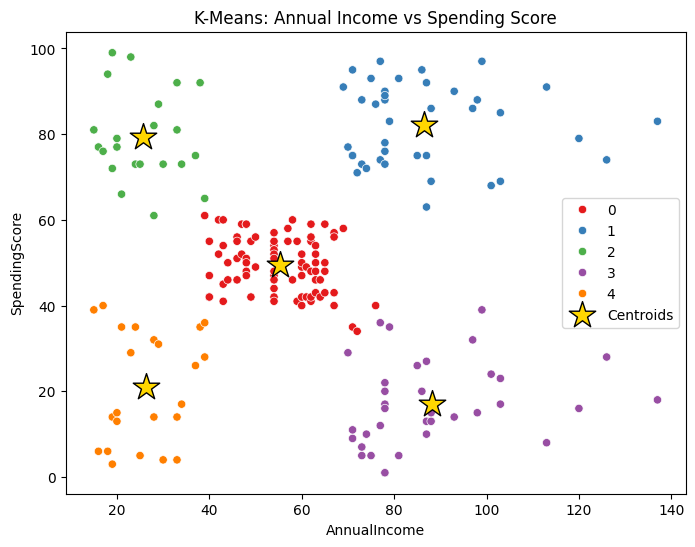

In [17]:
centers = scaler_2d.inverse_transform(km_2d.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(x='AnnualIncome', y='SpendingScore', hue='KMeans_Cluster', data=df, palette='Set1')
plt.scatter(centers[:, 0], centers[:, 1], marker='*', s=400, c='gold', edgecolors='black', label='Centroids')
plt.title('K-Means: Annual Income vs Spending Score')
plt.legend()
plt.savefig('kmeans_clusters.png')
plt.show()

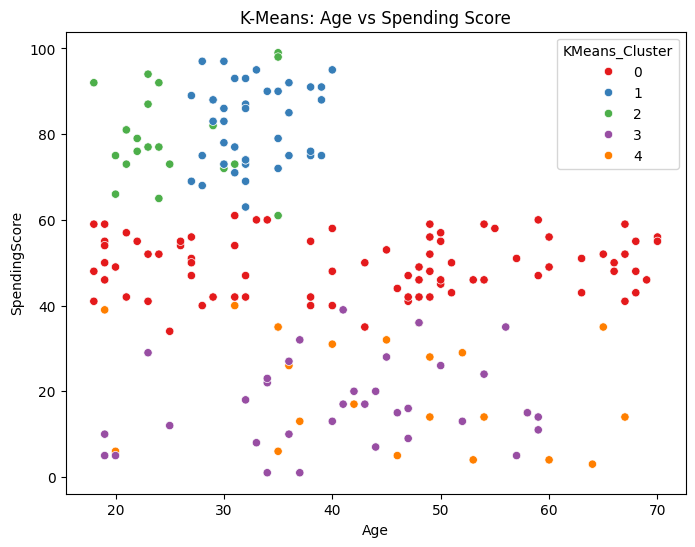

In [18]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Age', y='SpendingScore', hue='KMeans_Cluster', data=df, palette='Set1')
plt.title('K-Means: Age vs Spending Score')
plt.savefig('kmeans_age_spending.png')
plt.show()

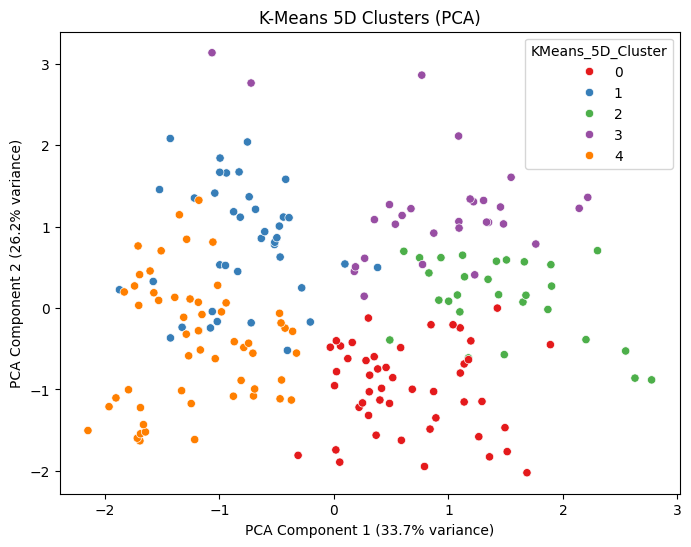

In [19]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_5d_scaled)
var = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df['KMeans_5D_Cluster'], palette='Set1')
plt.xlabel(f'PCA Component 1 ({var[0]:.1f}% variance)')
plt.ylabel(f'PCA Component 2 ({var[1]:.1f}% variance)')
plt.title('K-Means 5D Clusters (PCA)')
plt.savefig('kmeans_pca.png')
plt.show()

## 3.4 Profile K-Means Clusters

In [20]:
def get_persona(income, spend):
    if income >= 70 and spend >= 60:
        return 'Big Spenders'
    elif income >= 70 and spend <= 40:
        return 'Careful Spenders'
    elif income <= 40 and spend >= 60:
        return 'Young Aspirers'
    elif income <= 40 and spend <= 40:
        return 'Budget Shoppers'
    else:
        return 'Mainstream Shoppers'

def make_profile(data, col):
    p = data.groupby(col)[num_cols].mean().round(1)
    p['Customers'] = data.groupby(col).size()
    p['%Male'] = (data.groupby(col)['Gender_enc'].mean() * 100).round(1)
    p['%Female'] = 100 - p['%Male']
    p['Persona'] = [get_persona(i, s) for i, s in zip(p['AnnualIncome'], p['SpendingScore'])]
    return p.sort_values('SpendingScore', ascending=False)

km_profile = make_profile(df, 'KMeans_Cluster')
df['KMeans_Persona'] = df['KMeans_Cluster'].map(km_profile['Persona'])
km_profile

,Age,AnnualIncome,SpendingScore,Customers,%Male,%Female,Persona
KMeans_Cluster,,,,,,,
1,32.7,86.5,82.1,39,46.2,53.8,Big Spenders
2,25.3,25.7,79.4,22,40.9,59.1,Young Aspirers
0,42.7,55.3,49.5,81,40.7,59.3,Mainstream Shoppers
4,45.2,26.3,20.9,23,39.1,60.9,Budget Shoppers
3,41.1,88.2,17.1,35,54.3,45.7,Careful Spenders


**Personas (K-Means, unscaled means).**
- **Big Spenders** (39 customers; age 33, 86.5 k$, score 82): high income and high spending, the premium zone customers (the Zara / premium brand shopper).
- **Young Aspirers** (22; age 25, 25.7 k$, score 79): the youngest group, low income but spend almost as much as Big Spenders, the fast-fashion and value-brand shopper (Westside / H&M type).
- **Mainstream Shoppers** (81; age 43, 55.3 k$, score 49.5): average on every measure and the largest group (40%).
- **Careful Spenders** (35; age 41, 88.2 k$, score 17): highest income but lowest engagement, so they have money but do not spend it here.
- **Budget Shoppers** (23; age 45, 26.3 k$, score 21): low income, low spending, the oldest group, who go for deals.

Gender split is close to the 56/44 base rate in every cluster (Careful Spenders is the only one with more men, 54%), confirming gender is not a segment driver.

# Step 4: Agglomerative Hierarchical Clustering
## 4.1 Dendrogram Analysis

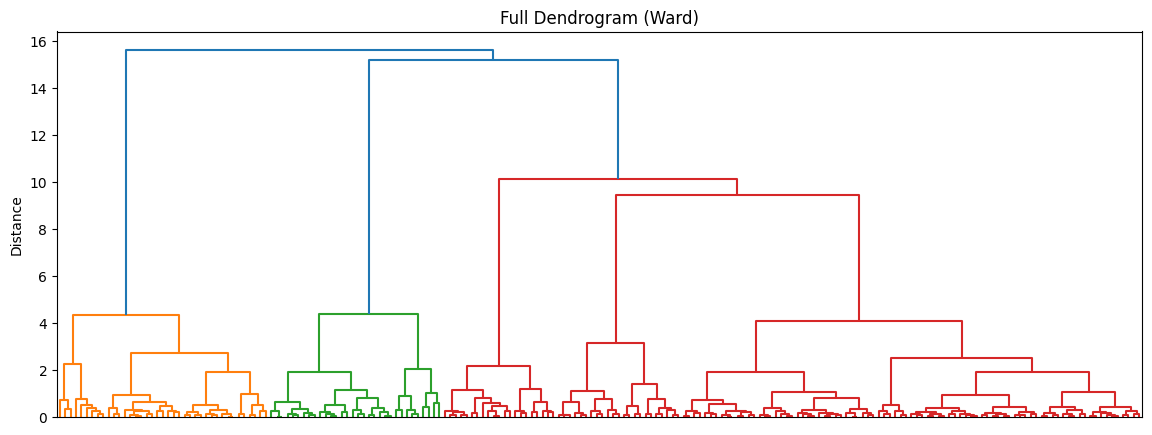

In [21]:
Z = linkage(X_2d_scaled, method='ward')

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True)
plt.title('Full Dendrogram (Ward)')
plt.ylabel('Distance')
plt.show()

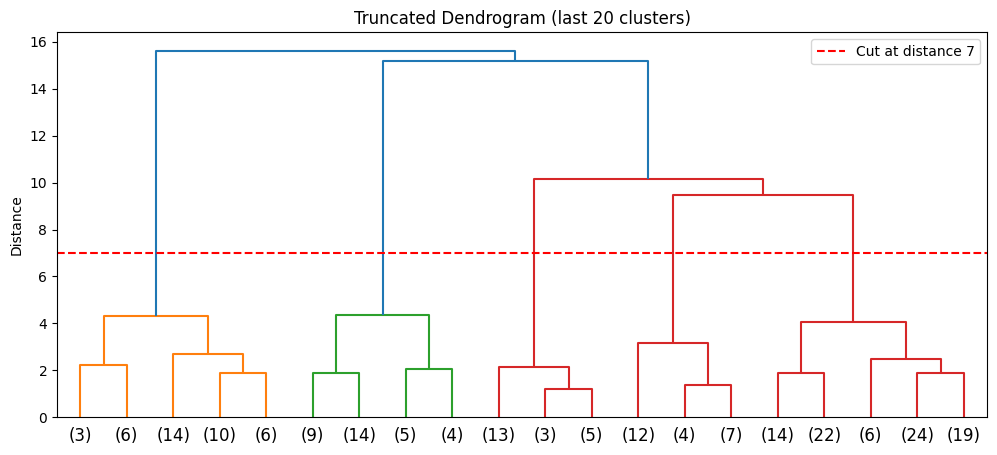

In [22]:
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=20)
plt.axhline(y=7, color='red', linestyle='--', label='Cut at distance 7')
plt.title('Truncated Dendrogram (last 20 clusters)')
plt.ylabel('Distance')
plt.legend()
plt.savefig('dendrogram.png')
plt.show()

n_chosen = 5

**Cut.** The longest vertical line that no horizontal line crosses lies between distances of about 4.4 and 9.4. A horizontal cut at **distance ≈ 7** crosses **5 branches, so 5 clusters**, which matches K-Means.

## 4.2 Train Agglomerative Models

In [23]:
results = []
labels_by_linkage = {}

for link in ['ward', 'complete', 'average']:
    model = AgglomerativeClustering(n_clusters=n_chosen, linkage=link)
    labels = model.fit_predict(X_2d_scaled)
    labels_by_linkage[link] = labels
    results.append([link, silhouette_score(X_2d_scaled, labels)])

link_df = pd.DataFrame(results, columns=['Linkage', 'Silhouette Score'])
print(link_df)

df['Agg_Cluster'] = labels_by_linkage['ward']

    Linkage  Silhouette Score
0      ward          0.553809
1  complete          0.553112
2   average          0.479426


**Linkage comparison.** Ward (0.5538) and complete (0.5531) are almost tied; average linkage is clearly worse (0.4794) because it produces a 3-customer cluster and a 102-customer cluster. **Ward is selected** (highest Silhouette, and balanced cluster sizes).

## 4.3 Visualise & Profile Hierarchical Clusters

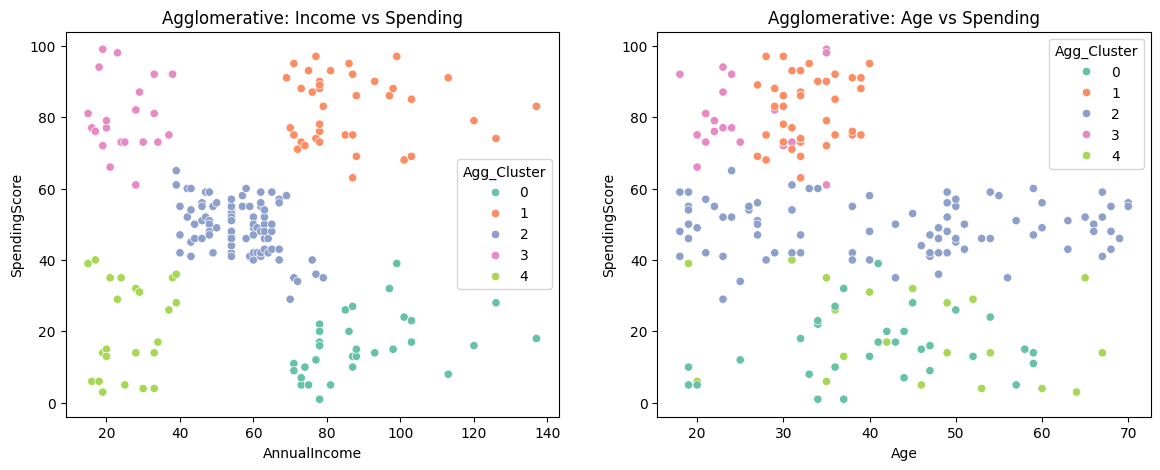

In [24]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x='AnnualIncome', y='SpendingScore', hue='Agg_Cluster', data=df, palette='Set2')
plt.title('Agglomerative: Income vs Spending')
plt.subplot(1, 2, 2)
sns.scatterplot(x='Age', y='SpendingScore', hue='Agg_Cluster', data=df, palette='Set2')
plt.title('Agglomerative: Age vs Spending')
plt.show()

In [25]:
agg_profile = make_profile(df, 'Agg_Cluster')
df['Agg_Persona'] = df['Agg_Cluster'].map(agg_profile['Persona'])
agg_profile

,Age,AnnualIncome,SpendingScore,Customers,%Male,%Female,Persona
Agg_Cluster,,,,,,,
1,32.7,86.5,82.1,39,46.2,53.8,Big Spenders
3,25.3,25.1,80.0,21,42.9,57.1,Young Aspirers
2,42.5,55.8,49.1,85,40.0,60.0,Mainstream Shoppers
4,45.2,26.3,20.9,23,39.1,60.9,Budget Shoppers
0,41.0,89.4,15.6,32,56.2,43.8,Careful Spenders


In [26]:
same = (df['KMeans_Persona'] == df['Agg_Persona']).sum()
print(f'Customers in the same segment by both algorithms: {same} of {len(df)}')
print(f'Agreement: {same / len(df) * 100:.1f}%')

Customers in the same segment by both algorithms: 196 of 200
Agreement: 98.0%


**Personas.** The hierarchical clusters carry the same personas as K-Means: Big Spenders (39), Young Aspirers (21), Mainstream Shoppers (85), Careful Spenders (32) and Budget Shoppers (23).

**Agreement with K-Means: 98.0%** (196 of 200 customers) by comparing persona names. Only 4 customers differ (3 K-Means Careful Spenders and 1 Young Aspirer are placed in the Mainstream group by Ward), all borderline points. This is higher than the 80–90% in the exam note because the five groups are compact and well-separated, and Ward minimises variance just as K-Means does.

# Step 5: DBSCAN Clustering
## 5.1 Tune Epsilon with the k-NN Distance Plot

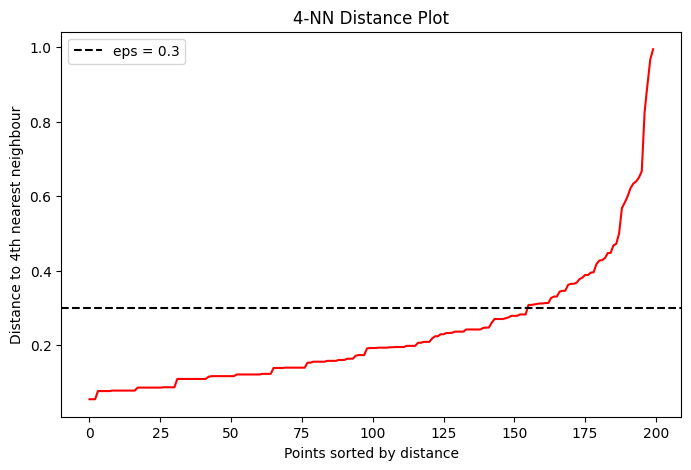

In [27]:
nn = NearestNeighbors(n_neighbors=4).fit(X_2d_scaled)
distances, _ = nn.kneighbors(X_2d_scaled)
k_dist = np.sort(distances[:, 3])

plt.figure(figsize=(8, 5))
plt.plot(k_dist, color='red')
plt.axhline(y=0.3, color='black', linestyle='--', label='eps = 0.3')
plt.title('4-NN Distance Plot')
plt.xlabel('Points sorted by distance')
plt.ylabel('Distance to 4th nearest neighbour')
plt.legend()
plt.savefig('knn_distance.png')
plt.show()

optimal_eps = 0.3

**Epsilon.** The 4-NN distance curve stays flat at low distances and then bends sharply upward at around **0.3**, so **eps = 0.3** is chosen: below it points are in dense regions, above it they are isolated fringe points.

## 5.2 Train DBSCAN

In [28]:
db = DBSCAN(eps=optimal_eps, min_samples=4, metric='euclidean')
df['DBSCAN_Cluster'] = db.fit_predict(X_2d_scaled)

n_clusters = len(set(df['DBSCAN_Cluster'])) - (1 if -1 in df['DBSCAN_Cluster'].values else 0)
n_noise = (df['DBSCAN_Cluster'] == -1).sum()
print('Clusters found:', n_clusters)
print(f'Noise points: {n_noise} ({n_noise / len(df) * 100:.1f}%)')

Clusters found: 8
Noise points: 23 (11.5%)


With eps = 0.3 and min_samples = 4, DBSCAN finds **8 clusters** and flags **23 customers (11.5%)** as noise. That is more clusters than the 5 natural segments, so it splits real segments too finely. The grid search in 5.3 tunes this.

## 5.3 Tune DBSCAN Hyperparameters

In [29]:
eps_list = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
min_samples_list = [3, 4, 5, 7, 10]
rows = []

for eps in eps_list:
    for ms in min_samples_list:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_2d_scaled)
        n_cl = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = (labels == -1).mean() * 100
        if n_cl >= 2 and noise_pct < 30:
            sil = silhouette_score(X_2d_scaled[labels != -1], labels[labels != -1])
        else:
            sil = np.nan
        rows.append([eps, ms, n_cl, round(noise_pct, 1), sil])

grid = pd.DataFrame(rows, columns=['eps', 'min_samples', 'clusters', 'noise_%', 'silhouette'])
grid

,eps,min_samples,clusters,noise_%,silhouette
0,0.2,3,13,22.0,0.469713
1,0.2,4,5,36.5,NaN
2,0.2,5,7,38.5,NaN
3,0.2,7,4,50.0,NaN
4,0.2,10,1,64.5,NaN
5,0.4,3,4,5.0,0.395381
6,0.4,4,3,7.0,0.457570
7,0.4,5,4,7.5,0.478059
8,0.4,7,4,10.0,0.494621
9,0.4,10,4,25.5,0.597195


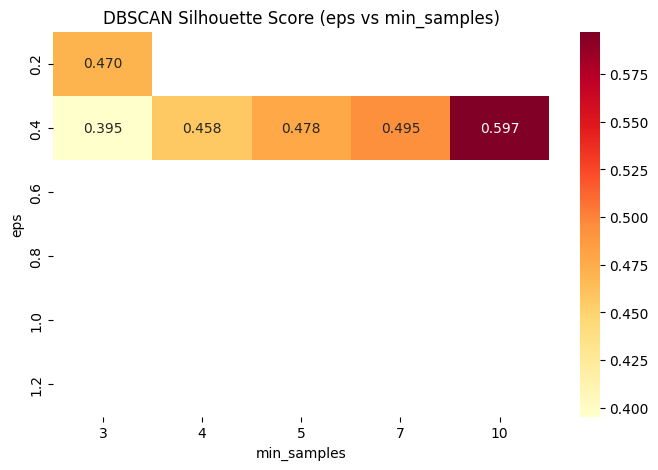

Best eps: 0.4  Best min_samples: 10
DBSCAN_Cluster
 1    87
-1    51
 2    29
 3    22
 0    11
Name: count, dtype: int64


In [30]:
heat = grid.pivot(index='eps', columns='min_samples', values='silhouette')
plt.figure(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.3f', cmap='YlOrRd')
plt.title('DBSCAN Silhouette Score (eps vs min_samples)')
plt.show()

best = grid.loc[grid['silhouette'].idxmax()]
best_eps = best['eps']
best_ms = int(best['min_samples'])
print('Best eps:', best_eps, ' Best min_samples:', best_ms)

db = DBSCAN(eps=best_eps, min_samples=best_ms)
df['DBSCAN_Cluster'] = db.fit_predict(X_2d_scaled)
print(df['DBSCAN_Cluster'].value_counts())

**What the grid shows.**
- At eps ≥ 0.6 everything merges into a single cluster, so those combinations are invalid; at eps = 0.2 noise is above 30% for almost every setting.
- Only eps = 0.2/min_samples = 3 and eps = 0.4 (all min_samples) are valid.
- The best Silhouette is **0.597 at eps = 0.4, min_samples = 10**, which is retrained above and now gives 4 clusters and 51 noise points (25.5%).

**Caution:** that high Silhouette is partly an artefact of discarding a quarter of the customers. With min_samples = 10 the small Budget Shoppers group is almost entirely labelled noise, so the four DBSCAN clusters are Big Spenders, Young Aspirers, Mainstream Shoppers and Careful Spenders.

## 5.4 Visualise & Profile DBSCAN Clusters

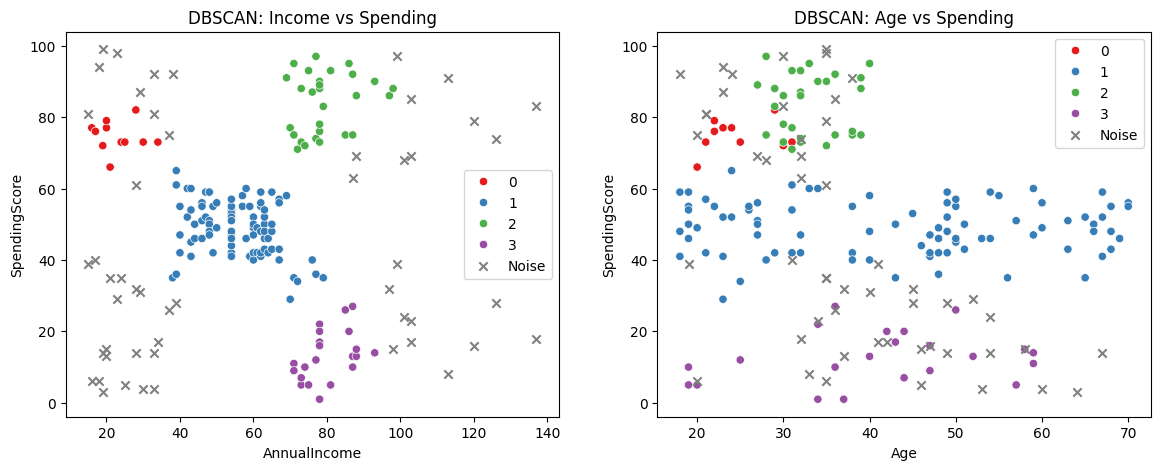

In [31]:
core = df[df['DBSCAN_Cluster'] != -1]
noise = df[df['DBSCAN_Cluster'] == -1]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x='AnnualIncome', y='SpendingScore', hue='DBSCAN_Cluster', data=core, palette='Set1')
plt.scatter(noise['AnnualIncome'], noise['SpendingScore'], c='grey', marker='x', label='Noise')
plt.title('DBSCAN: Income vs Spending')
plt.legend()
plt.subplot(1, 2, 2)
sns.scatterplot(x='Age', y='SpendingScore', hue='DBSCAN_Cluster', data=core, palette='Set1')
plt.scatter(noise['Age'], noise['SpendingScore'], c='grey', marker='x', label='Noise')
plt.title('DBSCAN: Age vs Spending')
plt.legend()
plt.savefig('dbscan_clusters.png')
plt.show()

In [32]:
db_profile = make_profile(core, 'DBSCAN_Cluster')
db_profile

,Age,AnnualIncome,SpendingScore,Customers,%Male,%Female,Persona
DBSCAN_Cluster,,,,,,,
2,32.9,79.2,83.6,29,41.4,58.6,Big Spenders
0,25.2,23.1,74.6,11,45.5,54.5,Young Aspirers
1,42.8,55.4,48.8,87,40.2,59.8,Mainstream Shoppers
3,41.0,80.2,12.7,22,68.2,31.8,Careful Spenders


In [33]:
print('Noise points:', len(noise))
print(noise[num_cols].mean().round(1))

Noise points: 51
Age              37.5
AnnualIncome     58.3
SpendingScore    44.5
dtype: float64


**DBSCAN personas (non-noise):** Big Spenders (29), Young Aspirers (11), Mainstream Shoppers (87) and Careful Spenders (22); the Budget Shoppers segment has disappeared.

**Noise shoppers (51 customers, 25.5%).** Their mean profile (age 37.5, income 58.3 k$, score 44.5) sits close to the overall dataset average, so they are **not extreme outliers**. They are fringe members of every segment that fall below the density threshold. They are shoppers who sit on the edges of, or between, the mainstream patterns rather than unusual customers.

# Step 6: Algorithm Comparison & Business Interpretation
## 6.1 Internal Metrics Comparison

In [34]:
def get_metrics(name, params, labels):
    mask = labels != -1
    X = X_2d_scaled[mask]
    y = labels[mask]
    return [name, params, len(set(y)),
            round(silhouette_score(X, y), 4),
            round(davies_bouldin_score(X, y), 4),
            round(calinski_harabasz_score(X, y), 1),
            round((~mask).mean() * 100, 1)]

comparison = pd.DataFrame([
    get_metrics('K-Means', 'k=5', df['KMeans_Cluster'].values),
    get_metrics('Agglomerative', 'n_clusters=5, linkage=ward', df['Agg_Cluster'].values),
    get_metrics('DBSCAN', f'eps={best_eps}, min_samples={best_ms}', df['DBSCAN_Cluster'].values),
], columns=['Algorithm', 'Hyperparameters', 'Clusters', 'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz', 'Noise %'])
comparison

,Algorithm,Hyperparameters,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Noise %
0,K-Means,k=5,5,0.5547,0.5722,248.6,0.0
1,Agglomerative,"n_clusters=5, linkage=ward",5,0.5538,0.5779,244.4,0.0
2,DBSCAN,"eps=0.4, min_samples=10",4,0.5972,0.4734,263.6,25.5


**Ranking by the three metrics.** DBSCAN ranks 1st on all three (Silhouette 0.597, Davies-Bouldin 0.473, Calinski-Harabasz 263.6), K-Means 2nd (0.555, 0.572, 248.6) and Agglomerative 3rd (0.554, 0.578, 244.4).

**Interpretation.** DBSCAN produced the most compact, well-separated clusters on paper, but its scores are computed after removing **25.5% of the customers** and it merges away a whole segment (Budget Shoppers), so the comparison is not like-for-like. K-Means and Agglomerative cover 100% of customers and are almost identical (98% agreement). For a model that must label every shopper, **K-Means is the best complete solution**.

## 6.2 Cluster Stability Check for K-Means

In [35]:
scores = []
for seed in [0, 7, 21, 42, 99]:
    km = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=seed)
    labels = km.fit_predict(X_2d_scaled)
    scores.append(silhouette_score(X_2d_scaled, labels))
    print(f'random_state={seed}: Silhouette = {scores[-1]:.4f}')

print(f'Mean = {np.mean(scores):.4f}, Std = {np.std(scores):.6f}')

random_state=0: Silhouette = 0.5547
random_state=7: Silhouette = 0.5547
random_state=21: Silhouette = 0.5547
random_state=42: Silhouette = 0.5547
random_state=99: Silhouette = 0.5547
Mean = 0.5547, Std = 0.000000


**Stable.** The Silhouette is identical (0.5547 ± 0.0000) for all five seeds. The five groups are compact and well separated in 2D, and `k-means++` with `n_init` restarts converges to the same partition every time, so the result does not depend on the random initialisation.

## Business Recommendation: Mall Shopper Segmentation
**To:** Retail Operations Director, Nexus Malls / Phoenix Marketcity  **From:** Junior Data Scientist, Retail Analytics

**Recommended algorithm: K-Means (k = 5, on income and spending score).** It reaches a Silhouette of **0.555**, Davies-Bouldin of **0.572** and Calinski-Harabasz of **248.6** while labelling **100%** of customers, and the result is fully stable across random seeds (0.5547 ± 0.0000). DBSCAN scores higher (0.597 / 0.473 / 263.6) but only after treating **25.5%** of shoppers as noise and losing the Budget Shoppers segment, and it cannot label a new customer. Agglomerative (Ward) gives practically the same result (Silhouette 0.554, 98% agreement with K-Means), which independently confirms the five segments. K-Means also gives a centroid per segment and assigns a new shopper instantly.

| Segment | Customers | Description | Retail strategy |
|---|---|---|---|
| **Big Spenders** | 39 | Age ~33, income 86.5 k$, score 82. High income, high spend. | Install a **premium lounge with curated luxury brand pop-ups** near the food court, plus early access to sales through the mall app. |
| **Young Aspirers** | 22 | Age ~25, income 25.7 k$, score 79. Low income, very high spend. | Run **student/youth deal days and fast-fashion pop-ups** with app-based points and instalment offers; keep them loyal with value. |
| **Mainstream Shoppers** | 81 | Age ~43, income 55 k$, score 49.5. The 40% core. | A **tiered loyalty scheme** (e.g. spend ₹X to unlock Silver/Gold rewards) and seasonal sales to nudge them up to the High Spend group. |
| **Careful Spenders** | 35 | Age ~41, income 88 k$, score 17. Money but low spending. | **Personalised invitations and curated events** (premium dining, home and lifestyle brands) to win back share of wallet; the biggest upside per customer. |
| **Budget Shoppers** | 23 | Age ~45, income 26 k$, score 21. Low income, low spend. | Place **value-for-money stores near the entrances**; send **₹50-off coupons via the mall app**, food-court combos; keep campaign cost low. |

**Additional data that would improve segmentation:** purchase category and basket data, visit frequency and dwell time from footfall sensors, loyalty-app behaviour (coupon redemption, app opens), store-level transactions, and demographic detail such as household type and distance travelled.

# Step 7: Pipeline & Deployment
## 7.1 Save the Pipeline and Build `classify_shopper()`

In [36]:
best_model = km_2d
persona_map = km_profile['Persona'].to_dict()

joblib.dump(scaler_2d, 'mall_scaler.pkl')
joblib.dump(best_model, 'mall_segmentation_model.pkl')

['mall_segmentation_model.pkl']

In [37]:
scaler = joblib.load('mall_scaler.pkl')
model = joblib.load('mall_segmentation_model.pkl')

def classify_shopper(age, annual_income, spending_score, gender=None):
    new = pd.DataFrame([[annual_income, spending_score]], columns=['AnnualIncome', 'SpendingScore'])
    cluster = int(model.predict(scaler.transform(new))[0])
    return cluster, persona_map[cluster]

new_shoppers = [(22, 'Female', 30, 85), (45, 'Male', 95, 15), (35, 'Female', 90, 88),
                (50, 'Male', 20, 10), (40, 'Female', 55, 50)]

rows = []
for age, gender, income, score in new_shoppers:
    cluster, persona = classify_shopper(age, income, score, gender)
    rows.append([age, gender, income, score, cluster, persona])

pd.DataFrame(rows, columns=['Age', 'Gender', 'AnnualIncome (k$)', 'SpendingScore', 'Cluster', 'Persona'])

,Age,Gender,AnnualIncome (k$),SpendingScore,Cluster,Persona
0,22,Female,30,85,2,Young Aspirers
1,45,Male,95,15,3,Careful Spenders
2,35,Female,90,88,1,Big Spenders
3,50,Male,20,10,4,Budget Shoppers
4,40,Female,55,50,0,Mainstream Shoppers


The best model (K-Means, 2D) and its scaler are saved with `joblib`. `classify_shopper()` returns the cluster label and persona for a new shopper (income in k$, as in the dataset).